### Perzeptron und Neuron

Mit diesem Notebook beginnt eine Reihe über neuronale Netze:

1. **Perzeptron und Neuron** (dieses Notebook): Wie rechnet ein einzelnes künstliches Neuron, was kann es und was
   nicht?
2. Gradientenabstieg: Wie misst man den Fehler eines Neurons und verkleinert ihn schrittweise?
3. Backpropagation: Wie lernt ein ganzes Netz?
4. PyTorch und Bildklassifikation
5. Convolutional Neural Networks
6. Sprachmodelle

#### Klassifikation

Viele Aufgaben, die neuronale Netze lösen, sind **Klassifikationen**: Ein Objekt soll einer von mehreren Klassen
zugeordnet werden. Zeigt ein Bild eine Katze oder einen Hund? Ist eine E-Mail Spam oder nicht?

Für solche Aufgaben ist es sehr schwer, Regeln von Hand zu programmieren. Welche Pixel machen eine Katze aus? Statt
Regeln zu schreiben, gibt man dem Rechner viele **Beispiele**, deren Klasse man schon kennt, z.B. 25000 Bilder, die
mit Katze oder Hund beschriftet sind. Daraus soll er lernen, auch neue Bilder richtig einzuordnen. Das nennt man
**maschinelles Lernen**.

Wir beginnen mit dem einfachsten Fall: Punkte in der Ebene, die zu einer von zwei Klassen gehören (1 oder 0).

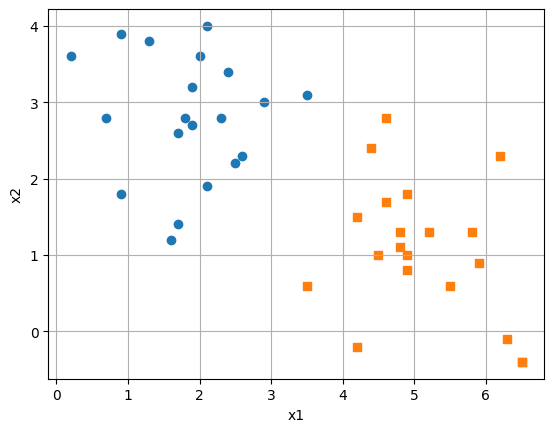

In [1]:
import random
import matplotlib.pyplot as plt

random.seed(3)
punkte = [(round(random.gauss(2, 0.8), 1), round(random.gauss(3, 0.8), 1)) for i in range(20)]
punkte += [(round(random.gauss(5, 0.8), 1), round(random.gauss(1.5, 0.8), 1)) for i in range(20)]
klassen = [1] * 20 + [0] * 20

def zeige_punkte(X, Y):
    for (x1, x2), y in zip(X, Y):
        plt.scatter(x1, x2, color='tab:blue' if y == 1 else 'tab:orange', marker='o' if y == 1 else 's')

zeige_punkte(punkte, klassen)
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid()
plt.show()

Die blauen Kreise gehören zur Klasse 1, die orangen Quadrate zur Klasse 0. Gesucht ist ein Verfahren, das für
jeden Punkt $(x_1, x_2)$, also auch für neue Punkte, die Klasse vorhersagt.

Im [Tensorflow Playground](https://playground.tensorflow.org/) kann man im Browser ausprobieren, wie ein neuronales
Netz solche Punkte klassifiziert.

### Das Perzeptron

Das **Perzeptron** wurde 1958 von Frank Rosenblatt vorgeschlagen, als stark vereinfachtes Modell einer
Nervenzelle. Es bekommt Inputs $x_1, x_2$ und multipliziert jeden mit einem **Gewicht** $w_1, w_2$. Ist die
gewichtete Summe mindestens so groß wie ein **Schwellwert** $s$, dann „feuert“ das Perzeptron und gibt 1 aus, sonst
0:

$$a = 1 \text{ falls } w_1 x_1 + w_2 x_2 \ge s, \text{ sonst } a = 0$$

Bringt man den Schwellwert auf die andere Seite, wird daraus $w_1 x_1 + w_2 x_2 - s \ge 0$. Den negativen
Schwellwert $b = -s$ nennt man **Bias**. Je größer der Bias, desto leichter feuert das Perzeptron. Damit rechnet das
Perzeptron in zwei Schritten:

<img src="perzeptron.png" width="750">

Die Funktion im zweiten Schritt heißt **Aktivierungsfunktion**, hier ist es eine **Stufenfunktion**. Gewichte und
Bias sind die **Parameter** des Perzeptrons. Sie legen fest, wie es sich verhält.

In [2]:
def stufe(z):
    if z >= 0:
        return 1
    return 0

def perzeptron(x1, x2, w1, w2, b):
    z = w1 * x1 + w2 * x2 + b
    return stufe(z)

w1, w2, b = 1, -2, -4
print(perzeptron(3, 2, w1, w2, b), perzeptron(3, -2, w1, w2, b))

0 1


Für $(3, 2)$ ist $z = 1 \cdot 3 - 2 \cdot 2 - 4 = -5$, das Perzeptron gibt 0 aus. Für $(3, -2)$ ist
$z = 3 + 4 - 4 = 3$, es gibt 1 aus.

#### Logische Funktionen

Bei Inputs 0 und 1 kann ein Perzeptron logische Funktionen berechnen. Für **OR** soll es feuern, sobald mindestens
ein Input 1 ist:

| $x_1$ | $x_2$ | OR |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 1 |

Mit $w_1 = w_2 = 1$ ist die Summe 0, 1 oder 2. Mit dem Bias $b = -0.5$ feuert das Perzeptron, sobald die Summe
mindestens 0.5 ist.

In [3]:
X = [(0, 0), (0, 1), (1, 0), (1, 1)]
Y_or = [0, 1, 1, 1]

for (x1, x2), y in zip(X, Y_or):
    print(x1, x2, '  Perzeptron:', perzeptron(x1, x2, 1, 1, -0.5), '  OR:', y)

0 0   Perzeptron: 0   OR: 0
0 1   Perzeptron: 1   OR: 1
1 0   Perzeptron: 1   OR: 1
1 1   Perzeptron: 1   OR: 1


`zip(X, Y_or)` durchläuft die beiden Listen gleichzeitig und liefert jeweils ein Paar aus Input und gewünschter
Ausgabe. `(x1, x2), y` packt dieses Paar gleich aus.

Für **AND** muss die Summe mindestens 1.5 sein, also $b = -1.5$. **NOT** hat nur einen Input: Mit $w = -1$ und
$b = 0.5$ feuert das Perzeptron genau für $x = 0$.

In [4]:
Y_and = [0, 0, 0, 1]
for (x1, x2), y in zip(X, Y_and):
    print(x1, x2, '  Perzeptron:', perzeptron(x1, x2, 1, 1, -1.5), '  AND:', y)

for x in [0, 1]:
    print('NOT', x, stufe(-1 * x + 0.5))

0 0   Perzeptron: 0   AND: 0
0 1   Perzeptron: 0   AND: 0
1 0   Perzeptron: 0   AND: 0
1 1   Perzeptron: 1   AND: 1
NOT 0 1
NOT 1 0


#### Was das Perzeptron geometrisch macht

Das Perzeptron feuert, wenn $w_1 x_1 + w_2 x_2 + b \ge 0$ ist. Die Punkte mit $w_1 x_1 + w_2 x_2 + b = 0$ liegen auf
einer **Geraden**. Für $w_2 \ne 0$ kann man nach $x_2$ auflösen:

$$x_2 = -\frac{w_1}{w_2} x_1 - \frac{b}{w_2}$$

Auf der einen Seite der Geraden gibt das Perzeptron 1 aus, auf der anderen 0. Das Perzeptron teilt die Ebene also
durch eine **Trenngerade** in zwei Hälften. Die Gewichte bestimmen die Richtung der Geraden, der Bias verschiebt
sie.

Die Funktion `zeige_perzeptron` färbt die Ebene nach der Ausgabe des Perzeptrons ein und zeichnet die Punkte dazu:

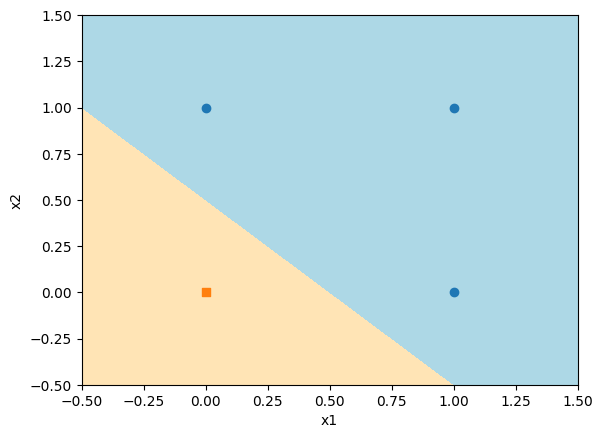

In [5]:
import numpy as np

def zeige_perzeptron(X, Y, w1, w2, b, bereich=(-0.5, 1.5, -0.5, 1.5)):
    x1min, x1max, x2min, x2max = bereich
    g1, g2 = np.meshgrid(np.linspace(x1min, x1max, 300), np.linspace(x2min, x2max, 300))
    a = (w1 * g1 + w2 * g2 + b >= 0)
    plt.contourf(g1, g2, a, levels=[-0.5, 0.5, 1.5], colors=['moccasin', 'lightblue'])
    zeige_punkte(X, Y)
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.show()

zeige_perzeptron(X, Y_or, 1, 1, -0.5)

Für OR ist die Trenngerade $x_2 = -x_1 + 0.5$. Im blauen Bereich feuert das Perzeptron, im orangen nicht. Für die
Punktwolke vom Anfang suchen wir eine Gerade von Hand. Die Gerade $x_2 = x_1 - 1$ scheint gut zu passen. Mit
$w_1 = -1$, $w_2 = 1$, $b = 1$ ist $z = -x_1 + x_2 + 1$, und das ist genau dann $\ge 0$, wenn $x_2 \ge x_1 - 1$.

falsch eingeordnet: 0


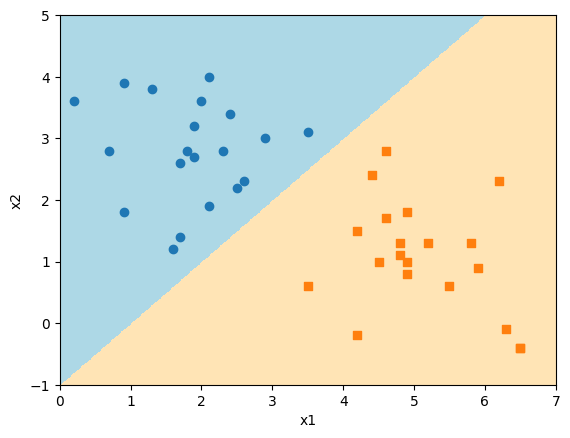

In [6]:
def fehler_zaehlen(X, Y, w1, w2, b):
    return sum(1 for (x1, x2), y in zip(X, Y) if perzeptron(x1, x2, w1, w2, b) != y)

print('falsch eingeordnet:', fehler_zaehlen(punkte, klassen, -1, 1, 1))
zeige_perzeptron(punkte, klassen, -1, 1, 1, bereich=(0, 7, -1, 5))

Alle 40 Punkte werden richtig eingeordnet.

#### Was ein Perzeptron nicht kann: XOR

**XOR** (exklusives Oder) liefert 1, wenn genau ein Input 1 ist:

| $x_1$ | $x_2$ | XOR |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

Zeichnet man die vier Punkte, sieht man das Problem: Die beiden Punkte mit Ausgabe 1 liegen sich diagonal gegenüber,
ebenso die beiden mit Ausgabe 0. Keine Gerade trennt sie.

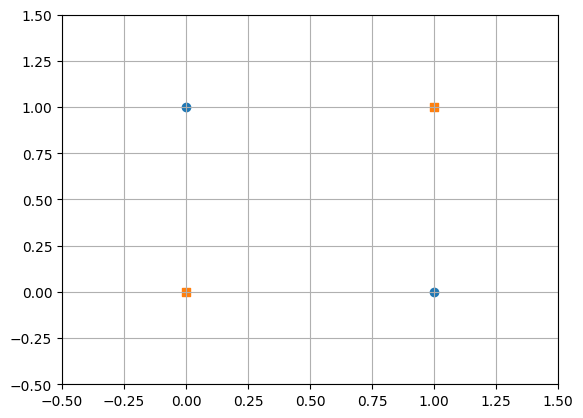

In [7]:
Y_xor = [0, 1, 1, 0]
zeige_punkte(X, Y_xor)
plt.xlim(-0.5, 1.5)
plt.ylim(-0.5, 1.5)
plt.grid()
plt.show()

Das lässt sich auch beweisen. Angenommen, ein Perzeptron mit $w_1, w_2, b$ berechnet XOR. Dann gilt:

- $(0, 0) \to 0$: $\quad b < 0$
- $(0, 1) \to 1$: $\quad w_2 + b \ge 0$
- $(1, 0) \to 1$: $\quad w_1 + b \ge 0$
- $(1, 1) \to 0$: $\quad w_1 + w_2 + b < 0$

Addiert man die zweite und dritte Ungleichung, erhält man $w_1 + w_2 + 2b \ge 0$, also $w_1 + w_2 + b \ge -b$. Wegen
$b < 0$ ist $-b > 0$, also $w_1 + w_2 + b > 0$. Das widerspricht der vierten Ungleichung.

Daten, die sich durch eine Gerade trennen lassen, heißen **linear trennbar**. Ein einzelnes Perzeptron kann nur
linear trennbare Daten richtig klassifizieren. Marvin Minsky und Seymour Papert haben 1969 in einem Buch genau solche
Grenzen beschrieben. Danach ließ das Interesse an neuronalen Netzen für viele Jahre nach.

#### Mehrere Perzeptronen: ein Netz

XOR lässt sich aus einfacheren Funktionen zusammensetzen: $x_1$ XOR $x_2$ ist dasselbe wie
($x_1$ OR $x_2$) AND NOT ($x_1$ AND $x_2$). NOT AND heißt **NAND**. Wir schalten drei Perzeptronen zusammen:
$h_1$ berechnet OR, $h_2$ berechnet NAND, und das dritte Perzeptron verknüpft beide mit AND.

<img src="xor_netz.png" width="480">

So ein Aufbau heißt **neuronales Netz**. $h_1$ und $h_2$ bilden die **versteckte Schicht** (hidden layer), weil man
ihre Werte von außen nicht sieht. Das letzte Perzeptron ist die **Ausgabeschicht**.

In [8]:
for (x1, x2), y in zip(X, Y_xor):
    h1 = perzeptron(x1, x2, 1, 1, -0.5)
    h2 = perzeptron(x1, x2, -1, -1, 1.5)
    a = perzeptron(h1, h2, 1, 1, -1.5)
    print(x1, x2, '  h1 =', h1, ' h2 =', h2, '  Netz:', a, '  XOR:', y)

0 0   h1 = 0  h2 = 1   Netz: 0   XOR: 0
0 1   h1 = 1  h2 = 1   Netz: 1   XOR: 1
1 0   h1 = 1  h2 = 1   Netz: 1   XOR: 1
1 1   h1 = 1  h2 = 0   Netz: 0   XOR: 0


Mit einer versteckten Schicht kann das Netz also mehr als ein einzelnes Perzeptron. Geometrisch: $h_1$ und $h_2$
ziehen jeweils eine Gerade, und das Ausgabeperzeptron kombiniert die beiden Halbebenen zu einem Streifen.

Die Parameter haben wir hier aber von Hand gesucht. Wie findet man sie automatisch?

### Die Perzeptron-Lernregel

Für ein einzelnes Perzeptron hat Rosenblatt eine einfache **Lernregel** angegeben. Man geht die Trainingsbeispiele
der Reihe nach durch. Für jedes Beispiel berechnet man die Ausgabe $a$ und vergleicht sie mit der richtigen Klasse
$y$:

- Ist $a = y$, ändert sich nichts.
- Sonst werden die Parameter verändert, mit einer **Lernrate** $lr$:

$$w_1 \leftarrow w_1 + lr \cdot (y - a) \cdot x_1, \quad w_2 \leftarrow w_2 + lr \cdot (y - a) \cdot x_2, \quad
b \leftarrow b + lr \cdot (y - a)$$

Hätte das Perzeptron feuern sollen ($y - a = 1$), werden die Gewichte der positiven Inputs größer und der Bias
größer. Hat es fälschlich gefeuert ($y - a = -1$), werden sie kleiner. Ein Durchgang durch alle Beispiele heißt
**Epoche**. Man wiederholt die Epochen, bis keine Fehler mehr auftreten.

In [9]:
def lernregel(X, Y, w1, w2, b, lr, epochen, ausgabe=False):
    for epoche in range(1, epochen + 1):
        fehler = 0
        for (x1, x2), y in zip(X, Y):
            a = perzeptron(x1, x2, w1, w2, b)
            if a != y:
                fehler += 1
                w1 = w1 + lr * (y - a) * x1
                w2 = w2 + lr * (y - a) * x2
                b = b + lr * (y - a)
            if ausgabe:
                print(epoche, (x1, x2), 'y =', y, 'a =', a, '  neu:', w1, w2, b)
        if fehler == 0:
            return w1, w2, b, epoche
    return w1, w2, b, None

print(lernregel(X, Y_or, 0, 0, 0, 1, 20, ausgabe=True))

1 (0, 0) y = 0 a = 1   neu: 0 0 -1
1 (0, 1) y = 1 a = 0   neu: 0 1 0
1 (1, 0) y = 1 a = 1   neu: 0 1 0
1 (1, 1) y = 1 a = 1   neu: 0 1 0
2 (0, 0) y = 0 a = 1   neu: 0 1 -1
2 (0, 1) y = 1 a = 1   neu: 0 1 -1
2 (1, 0) y = 1 a = 0   neu: 1 1 0
2 (1, 1) y = 1 a = 1   neu: 1 1 0
3 (0, 0) y = 0 a = 1   neu: 1 1 -1
3 (0, 1) y = 1 a = 1   neu: 1 1 -1
3 (1, 0) y = 1 a = 1   neu: 1 1 -1
3 (1, 1) y = 1 a = 1   neu: 1 1 -1
4 (0, 0) y = 0 a = 0   neu: 1 1 -1
4 (0, 1) y = 1 a = 1   neu: 1 1 -1
4 (1, 0) y = 1 a = 1   neu: 1 1 -1
4 (1, 1) y = 1 a = 1   neu: 1 1 -1
(1, 1, -1, 4)


Für OR ist nach der dritten Epoche alles richtig, die vierte Epoche läuft ohne Fehler durch. Das Perzeptron hat
$w_1 = w_2 = 1$ und $b = -1$ gelernt. Das sind andere Parameter als unsere, aber sie berechnen ebenfalls OR.

Auch die Punktwolke lernt das Perzeptron:

-0.75 1.1 0.1 nach 8 Epochen
falsch eingeordnet: 0


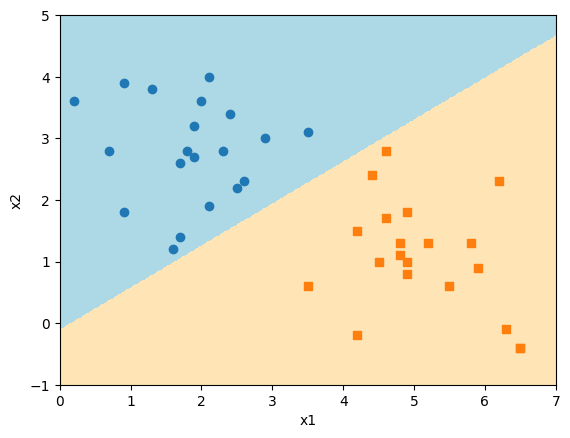

In [10]:
w1, w2, b, epochen = lernregel(punkte, klassen, 0, 0, 0, 0.1, 1000)
print(round(w1, 4), round(w2, 4), round(b, 4), 'nach', epochen, 'Epochen')
print('falsch eingeordnet:', fehler_zaehlen(punkte, klassen, w1, w2, b))
zeige_perzeptron(punkte, klassen, w1, w2, b, bereich=(0, 7, -1, 5))

Für linear trennbare Daten findet die Lernregel nach endlich vielen Schritten immer eine Trenngerade, das ist der
**Konvergenzsatz** für das Perzeptron. Bei XOR gibt es keine Trenngerade, die Lernregel kommt nie an:

In [11]:
print(lernregel(X, Y_xor, 0, 0, 0, 1, 1000))

(-1, 0, 0, None)


Nach 1000 Epochen gibt es immer noch Fehler (`None` statt einer Epochenzahl).

#### Warum die Lernregel für Netze nicht reicht

Für das XOR-Netz bräuchten wir eine Lernregel für alle drei Perzeptronen. Für das Ausgabeperzeptron kennen wir die
richtige Ausgabe $y$. Für $h_1$ und $h_2$ aber nicht: Niemand sagt uns, was die versteckten Perzeptronen ausgeben
sollen.

Eine andere Idee: Wir messen, wie viele Beispiele das Netz falsch einordnet, drehen ein wenig an einem Parameter und
schauen, ob es besser geworden ist. Mit der Stufenfunktion klappt das aber nicht. Wir probieren es an einem
Perzeptron für OR mit schlechten Parametern:

In [12]:
for w1 in [-1, -1.1, -0.9]:
    print('w1 =', w1, [perzeptron(x1, x2, w1, 1, -1.5) for x1, x2 in X], ' OR:', Y_or)

w1 = -1 [0, 0, 0, 0]  OR: [0, 1, 1, 1]
w1 = -1.1 [0, 0, 0, 0]  OR: [0, 1, 1, 1]
w1 = -0.9 [0, 0, 0, 0]  OR: [0, 1, 1, 1]


Ob wir $w_1$ etwas kleiner oder etwas größer machen, die Ausgaben bleiben gleich. Die Stufenfunktion springt nur an
einer Stelle, sonst ist sie flach. Eine kleine Änderung eines Parameters ändert fast nie die Ausgabe, und wir
erfahren nicht, in welche Richtung wir drehen sollen.

### Das Neuron

Die Lösung: Wir ersetzen die Stufe durch eine Funktion ohne Sprung, die **Sigmoidfunktion**

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Ein Perzeptron mit Sigmoid statt Stufe nennen wir **Neuron**.

<img src="neuron.png" width="750">

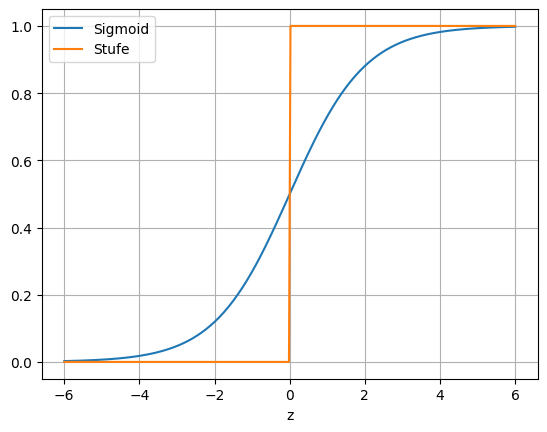

0.5 0.8807970779778823 0.11920292202211755 0.9975273768433653


In [13]:
import math

def sigmoid(z):
    return 1 / (1 + math.exp(-z))

z = np.linspace(-6, 6, 300)
plt.plot(z, 1 / (1 + np.exp(-z)), label='Sigmoid')
plt.plot(z, z >= 0, label='Stufe')
plt.xlabel('z')
plt.legend()
plt.grid()
plt.show()

print(sigmoid(0), sigmoid(2), sigmoid(-2), sigmoid(6))

Die Sigmoidfunktion geht wie die Stufe von 0 nach 1, aber stetig: Für große $z$ ist sie fast 1, für kleine fast 0,
bei $z = 0$ ist sie genau 0.5. Ihre Werte liegen immer zwischen 0 und 1. Man kann sie deshalb als
**Wahrscheinlichkeit** lesen: $a = 0.88$ heißt, das Neuron hält die Klasse 1 für wahrscheinlich, mit 88 Prozent.

Jetzt sehen wir auch kleine Änderungen:

In [14]:
def neuron(x1, x2, w1, w2, b):
    return sigmoid(w1 * x1 + w2 * x2 + b)

for w1 in [-1, -1.1, -0.9]:
    print('w1 =', w1, [round(neuron(x1, x2, w1, 1, -1.5), 4) for x1, x2 in X], ' OR:', Y_or)

w1 = -1 [0.1824, 0.3775, 0.0759, 0.1824]  OR: [0, 1, 1, 1]
w1 = -1.1 [0.1824, 0.3775, 0.0691, 0.168]  OR: [0, 1, 1, 1]
w1 = -0.9 [0.1824, 0.3775, 0.0832, 0.1978]  OR: [0, 1, 1, 1]


Wird $w_1$ größer, steigen die Ausgaben für $(1, 0)$ und $(1, 1)$, die beide 1 sein sollen. Wird $w_1$ kleiner,
sinken sie. Jetzt wissen wir also, in welche Richtung wir $w_1$ drehen müssen. Genau diese Information nutzt der
Gradientenabstieg im nächsten Notebook.

#### Neuron und Trenngerade

Das Neuron entscheidet sich für Klasse 1, wenn $a \ge 0.5$ ist, also wenn $z \ge 0$ ist. Die Trenngerade ist also
dieselbe wie beim Perzeptron mit denselben Parametern. Zusätzlich sagt der Wert $a$, wie sicher sich das Neuron ist:
Weit weg von der Geraden ist $a$ nahe bei 0 oder 1, nahe an der Geraden ungefähr 0.5.

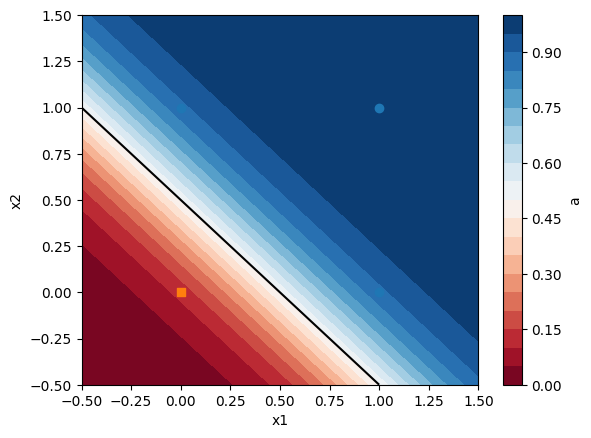

0 0 0.1192
0 1 0.8808
1 0 0.8808
1 1 0.9975


In [15]:
def zeige_neuron(X, Y, w1, w2, b, bereich=(-0.5, 1.5, -0.5, 1.5)):
    x1min, x1max, x2min, x2max = bereich
    g1, g2 = np.meshgrid(np.linspace(x1min, x1max, 300), np.linspace(x2min, x2max, 300))
    a = 1 / (1 + np.exp(-(w1 * g1 + w2 * g2 + b)))
    plt.contourf(g1, g2, a, levels=20, cmap='RdBu', vmin=0, vmax=1)
    plt.colorbar(label='a')
    plt.contour(g1, g2, a, levels=[0.5], colors='black')
    zeige_punkte(X, Y)
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.show()

zeige_neuron(X, Y_or, 4, 4, -2)
for x1, x2 in X:
    print(x1, x2, round(neuron(x1, x2, 4, 4, -2), 4))

Mit $w_1 = w_2 = 4$ und $b = -2$ ist das Neuron bei $(0, 0)$ zu 88 Prozent sicher, dass die Klasse 0 ist
($a = 0.1192$), und bei $(1, 1)$ fast völlig sicher, dass sie 1 ist.

#### Andere Aktivierungsfunktionen

Neben der Sigmoidfunktion gibt es weitere Aktivierungsfunktionen. Die wichtigste ist **ReLU** (rectified linear
unit): $ReLU(z) = \max(0, z)$. Sie lässt positive Werte unverändert durch und macht aus negativen eine 0. ReLU wird
in den versteckten Schichten großer Netze benutzt (mehr dazu in Backpropagation). Für die Ausgabe einer
Ja-Nein-Entscheidung nimmt man Sigmoid, weil ihre Werte zwischen 0 und 1 liegen.

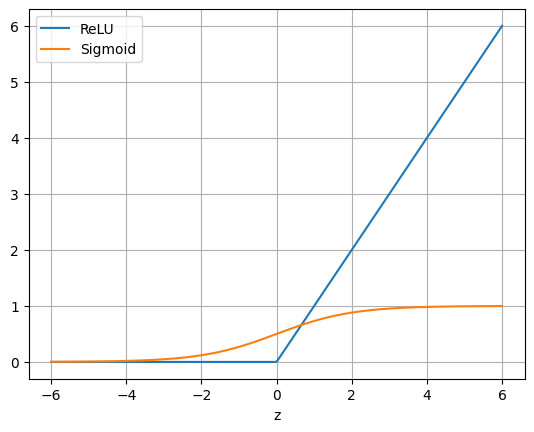

In [16]:
plt.plot(z, np.maximum(0, z), label='ReLU')
plt.plot(z, 1 / (1 + np.exp(-z)), label='Sigmoid')
plt.xlabel('z')
plt.legend()
plt.grid()
plt.show()

### Zusammenfassung

- Ein **Perzeptron** berechnet $z = w_1 x_1 + w_2 x_2 + b$ und gibt 1 aus, wenn $z \ge 0$, sonst 0.
- Geometrisch teilt es die Ebene durch eine **Trenngerade**. Es kann deshalb nur **linear trennbare** Daten richtig
  klassifizieren, z.B. AND und OR, aber nicht XOR.
- Mehrere Perzeptronen in Schichten (ein **Netz**) können mehr, z.B. XOR.
- Die **Perzeptron-Lernregel** findet für linear trennbare Daten die Parameter eines einzelnen Perzeptrons. Für Netze
  funktioniert sie nicht, weil man die richtigen Ausgaben der versteckten Schicht nicht kennt.
- Ein **Neuron** benutzt statt der Stufe die Sigmoidfunktion. Seine Ausgabe liegt zwischen 0 und 1 und ändert sich
  stetig mit den Parametern. Dadurch erkennt man, in welche Richtung man die Parameter verändern muss.

Im nächsten Notebook messen wir den Fehler eines Neurons und verkleinern ihn mit dem **Gradientenabstieg**.